In [3]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Base_de_Datos_dynamic_pricing.csv')

In [4]:
tabla_contingencia = pd.crosstab(
    df['Customer_Loyalty_Status'],
    df['Vehicle_Type'],
    margins=True,
    margins_name='Total'
)
print("Tabla de contingencia (frecuencias observadas):")
print(tabla_contingencia)

Tabla de contingencia (frecuencias observadas):
Vehicle_Type             Economy  Premium  Total
Customer_Loyalty_Status                         
Gold                         153      160    313
Regular                      144      176    320
Silver                       181      186    367
Total                        478      522   1000


In [5]:
tabla_sin_totales = tabla_contingencia.iloc[:-1, :-1]

chi2, p_value, gl, frecuencias_esperadas = chi2_contingency(tabla_sin_totales)

print(f"Estadístico Chi-Cuadrado (χ²): {chi2:.4f}")
print(f"Grados de libertad: {gl}")
print(f"Valor p: {p_value:.6f}")
print(f"¿Se rechaza H0 (α=0.05)?: {'Sí' if p_value < 0.05 else 'No'}")


freq_esperadas_df = pd.DataFrame(
    frecuencias_esperadas,
    index=tabla_sin_totales.index,
    columns=tabla_sin_totales.columns
)
print("\nFrecuencias esperadas:")
print(freq_esperadas_df.round(2))

Estadístico Chi-Cuadrado (χ²): 1.4916
Grados de libertad: 2
Valor p: 0.474365
¿Se rechaza H0 (α=0.05)?: No

Frecuencias esperadas:
Vehicle_Type             Economy  Premium
Customer_Loyalty_Status                  
Gold                      149.61   163.39
Regular                   152.96   167.04
Silver                    175.43   191.57


**En la guia no decia graficar** pero me parecio interasante y lo termine graficando

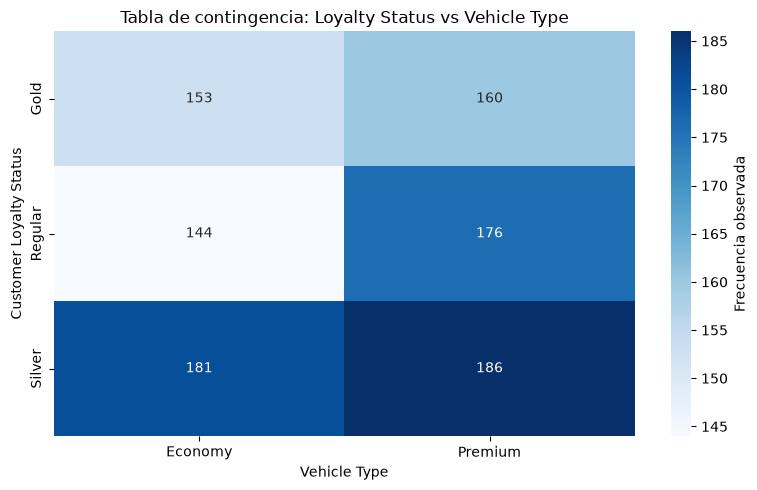

In [6]:
plt.figure(figsize=(8, 5))
sns.heatmap(tabla_sin_totales, annot=True, fmt='d', cmap='Blues',
            cbar_kws={'label': 'Frecuencia observada'})
plt.title('Tabla de contingencia: Loyalty Status vs Vehicle Type')
plt.ylabel('Customer Loyalty Status')
plt.xlabel('Vehicle Type')
plt.tight_layout()
plt.show()